In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
!pip install streamlit

Defaulting to user installation because normal site-packages is not writeable


In [7]:
df = pd.read_csv(r"C:\Users\DELL\Downloads\paddy_dataset_1.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (280, 33)


,Hectares,Agriblock,Variety,Soil_Type,Nursery_Type,Seed_Rate_Kg,DAP_Kg,Urea_Kg,Potash_Kg,Micronutrients_Kg,...,Temperature_Category,Total_Fertilizer_Kg,Fertilizer_Intensity,Nutrient_Balance_Index,Total_Water_Availability_mm,Water_Availability_Category,Weather_Stress_Index,Weather_Stress_Level,Yield_per_Water_Index,Yield_per_Fertilizer_Index
0,1.13,Kallakurichi,delux ponni,clay,wet,36.4,49.4,90.2,23.5,20.6,...,Optimal,183.7,High Input,0.375751,457.9,Adequate Water,0.411746,Moderate Stress,9.423455,23.489385
1,5.81,Panruti,CO_43,clay,dry,33.0,39.1,75.5,24.3,20.4,...,Optimal,159.3,Moderate Input,0.372786,422.9,Water Deficit,0.087989,Low Stress,8.512651,22.598870
2,2.94,Kallakurichi,delux ponni,alluvial,dry,37.8,44.2,71.5,18.6,21.3,...,High Temperature,155.6,Moderate Input,0.372934,448.4,Water Deficit,0.817989,High Stress,8.028546,23.136247
3,1.71,Cuddalore,delux ponni,clay,dry,35.2,48.2,60.5,30.4,23.3,...,Optimal,162.4,Moderate Input,0.354313,469.1,High Water Availability,0.336032,Moderate Stress,9.366873,27.056650
4,2.79,Kallakurichi,CO_43,clay,dry,39.1,48.4,77.4,16.4,18.0,...,Optimal,160.2,Moderate Input,0.375879,457.0,Adequate Water,0.598201,Moderate Stress,9.315098,26.573034


In [8]:
df.shape
df.columns
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Hectares                     280 non-null    float64
 1   Agriblock                    280 non-null    object 
 2   Variety                      280 non-null    object 
 3   Soil_Type                    280 non-null    object 
 4   Nursery_Type                 280 non-null    object 
 5   Seed_Rate_Kg                 280 non-null    float64
 6   DAP_Kg                       280 non-null    float64
 7   Urea_Kg                      280 non-null    float64
 8   Potash_Kg                    280 non-null    float64
 9   Micronutrients_Kg            280 non-null    float64
 10  Pest_Control_ml              280 non-null    float64
 11  Total_Rainfall_mm            280 non-null    float64
 12  Total_Irrigation_mm          280 non-null    float64
 13  Average_Min_Temp_C  

,Hectares,Seed_Rate_Kg,DAP_Kg,Urea_Kg,Potash_Kg,Micronutrients_Kg,Pest_Control_ml,Total_Rainfall_mm,Total_Irrigation_mm,Average_Min_Temp_C,...,Average_Humidity_pct,Average_Wind_Speed_Knots,Trash_Bundles,Paddy_Yield_Kg_per_Hectare,Total_Fertilizer_Kg,Nutrient_Balance_Index,Total_Water_Availability_mm,Weather_Stress_Index,Yield_per_Water_Index,Yield_per_Fertilizer_Index
count,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,...,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000
mean,3.414607,30.685357,48.426429,69.133571,25.196429,19.118571,715.042857,434.531071,20.560000,17.988214,...,82.241786,7.917143,92.867857,4244.442857,161.875000,0.363592,455.091071,0.474999,9.331650,26.456617
std,1.514203,5.311747,7.823103,12.024504,5.375471,3.521772,147.196033,10.347115,1.239193,1.570393,...,3.599672,1.898667,15.314635,368.897238,16.962339,0.009160,10.134481,0.168817,0.842643,3.193509
min,0.820000,20.000000,30.000000,39.800000,12.100000,12.000000,400.000000,401.100000,17.000000,14.000000,...,70.100000,3.500000,51.000000,3600.000000,118.600000,0.339361,422.100000,0.075926,7.427275,19.252049
25%,2.080000,27.000000,42.975000,60.275000,21.175000,16.750000,607.750000,427.750000,19.700000,16.900000,...,79.775000,6.500000,83.000000,3979.750000,150.375000,0.357257,448.825000,0.348016,8.756260,24.122552
50%,3.400000,30.650000,48.150000,69.700000,25.400000,19.150000,708.000000,435.000000,20.500000,18.100000,...,82.400000,7.950000,92.000000,4280.000000,162.400000,0.363603,455.200000,0.479868,9.361753,26.468097
75%,4.840000,34.500000,53.925000,76.725000,29.100000,21.525000,813.250000,440.225000,21.400000,18.900000,...,84.600000,9.300000,104.000000,4501.000000,174.600000,0.369914,461.050000,0.582963,9.952137,28.422231
max,5.940000,45.000000,69.800000,98.300000,38.100000,28.000000,1061.000000,464.000000,24.700000,22.000000,...,91.700000,12.500000,134.000000,5135.000000,219.700000,0.389751,484.700000,0.870370,11.580965,37.073579


In [9]:
# Farm size categories
df["Farm_Size_Group"] = pd.qcut(
    df["Hectares"],
    q=3,
    labels=["Small", "Medium", "Large"]
)


# Rainfall categories
df["Rainfall_Group"] = pd.qcut(
    df["Total_Rainfall_mm"],
    q=4,
    labels=["Low", "Moderate", "High", "Very High"]
)


# Fertilizer categories
df["Fertilizer_Group"] = pd.qcut(
    df["Total_Fertilizer_Kg"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)


# Temperature categories
df["Temperature_Group"] = pd.qcut(
    df["Average_Max_Temp_C"],
    q=3,
    labels=["Low Temperature", "Optimal Temperature", "High Temperature"]
)

print(df[
    [
        "Farm_Size_Group",
        "Rainfall_Group",
        "Fertilizer_Group",
        "Temperature_Group"
    ]
].head())

  Farm_Size_Group Rainfall_Group Fertilizer_Group Temperature_Group
0           Small           High        Very High   Low Temperature
1           Large            Low           Medium   Low Temperature
2          Medium            Low           Medium  High Temperature
3           Small      Very High             High   Low Temperature
4          Medium           High           Medium  High Temperature


In [10]:
# Farm Size analysis
farm_subset = df.groupby(
    "Farm_Size_Group",
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()


# Soil Type analysis
soil_subset = df.groupby(
    "Soil_Type"
)["Paddy_Yield_Kg_per_Hectare"].mean()


# Variety analysis
variety_subset = df.groupby(
    "Variety"
)["Paddy_Yield_Kg_per_Hectare"].mean()


print("Average Yield by Farm Size:")
print(farm_subset)

print("\nAverage Yield by Soil Type:")
print(soil_subset)

print("\nAverage Yield by Variety:")
print(variety_subset)

Average Yield by Farm Size:
Farm_Size_Group
Small     4276.882979
Medium    4277.494624
Large     4178.602151
Name: Paddy_Yield_Kg_per_Hectare, dtype: float64

Average Yield by Soil Type:
Soil_Type
alluvial    4325.932331
clay        4170.714286
Name: Paddy_Yield_Kg_per_Hectare, dtype: float64

Average Yield by Variety:
Variety
CO_43          4364.579710
delux ponni    4247.657143
ponmani        4163.056604
Name: Paddy_Yield_Kg_per_Hectare, dtype: float64


In [11]:
# Farm Size + Soil Type
subset_2_1 = df.groupby(
    ["Farm_Size_Group", "Soil_Type"],
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()


# Rainfall + Fertilizer
subset_2_2 = df.groupby(
    ["Rainfall_Group", "Fertilizer_Group"],
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()


# Temperature + Rainfall
subset_2_3 = df.groupby(
    ["Temperature_Group", "Rainfall_Group"],
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()


print("Farm Size + Soil Type:")
print(subset_2_1)

print("\nRainfall + Fertilizer:")
print(subset_2_2)

print("\nTemperature + Rainfall:")
print(subset_2_3)

Farm Size + Soil Type:
Farm_Size_Group  Soil_Type
Small            alluvial     4367.045455
                 clay         4197.540000
Medium           alluvial     4330.404255
                 clay         4223.434783
Large            alluvial     4277.857143
                 clay         4096.862745
Name: Paddy_Yield_Kg_per_Hectare, dtype: float64

Rainfall + Fertilizer:
Rainfall_Group  Fertilizer_Group
Low             Low                 4093.777778
                Medium              4195.312500
                High                4280.850000
                Very High           4387.250000
Moderate        Low                 4174.590909
                Medium              4106.769231
                High                4451.277778
                Very High           4441.736842
High            Low                 4241.857143
                Medium              4262.833333
                High                4201.800000
                Very High           4295.933333
Very High       

In [12]:
# Farm Size + Soil Type + Rainfall
subset_3_1 = df.groupby(
    [
        "Farm_Size_Group",
        "Soil_Type",
        "Rainfall_Group"
    ],
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()


# Variety + Rainfall + Fertilizer
subset_3_2 = df.groupby(
    [
        "Variety",
        "Rainfall_Group",
        "Fertilizer_Group"
    ],
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()


# Soil + Temperature + Fertilizer
subset_3_3 = df.groupby(
    [
        "Soil_Type",
        "Temperature_Group",
        "Fertilizer_Group"
    ],
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()


print("Farm Size + Soil Type + Rainfall:")
print(subset_3_1)

print("\nVariety + Rainfall + Fertilizer:")
print(subset_3_2)

print("\nSoil + Temperature + Fertilizer:")
print(subset_3_3)

Farm Size + Soil Type + Rainfall:
Farm_Size_Group  Soil_Type  Rainfall_Group
Small            alluvial   Low               4249.416667
                            Moderate          4350.300000
                            High              4478.250000
                            Very High         4391.500000
                 clay       Low               4301.357143
                            Moderate          4289.300000
                            High              4204.833333
                            Very High         4021.928571
Medium           alluvial   Low               4301.076923
                            Moderate          4393.923077
                            High              4349.200000
                            Very High         4272.909091
                 clay       Low               4234.400000
                            Moderate          4310.076923
                            High              4172.857143
                            Very High         4189.64

In [13]:
full_subset = df.groupby(
    [
        "Farm_Size_Group",
        "Soil_Type",
        "Rainfall_Group",
        "Fertilizer_Group"
    ],
    observed=False
)["Paddy_Yield_Kg_per_Hectare"].mean()

print(full_subset)

Farm_Size_Group  Soil_Type  Rainfall_Group  Fertilizer_Group
Small            alluvial   Low             Low                 4043.000000
                                            Medium              4178.666667
                                            High                4117.500000
                                            Very High           4683.333333
                            Moderate        Low                 4086.250000
                                                                   ...     
Large            clay       High            Very High           4186.666667
                            Very High       Low                 3951.000000
                                            Medium              3804.500000
                                            High                4217.000000
                                            Very High           4366.000000
Name: Paddy_Yield_Kg_per_Hectare, Length: 96, dtype: float64


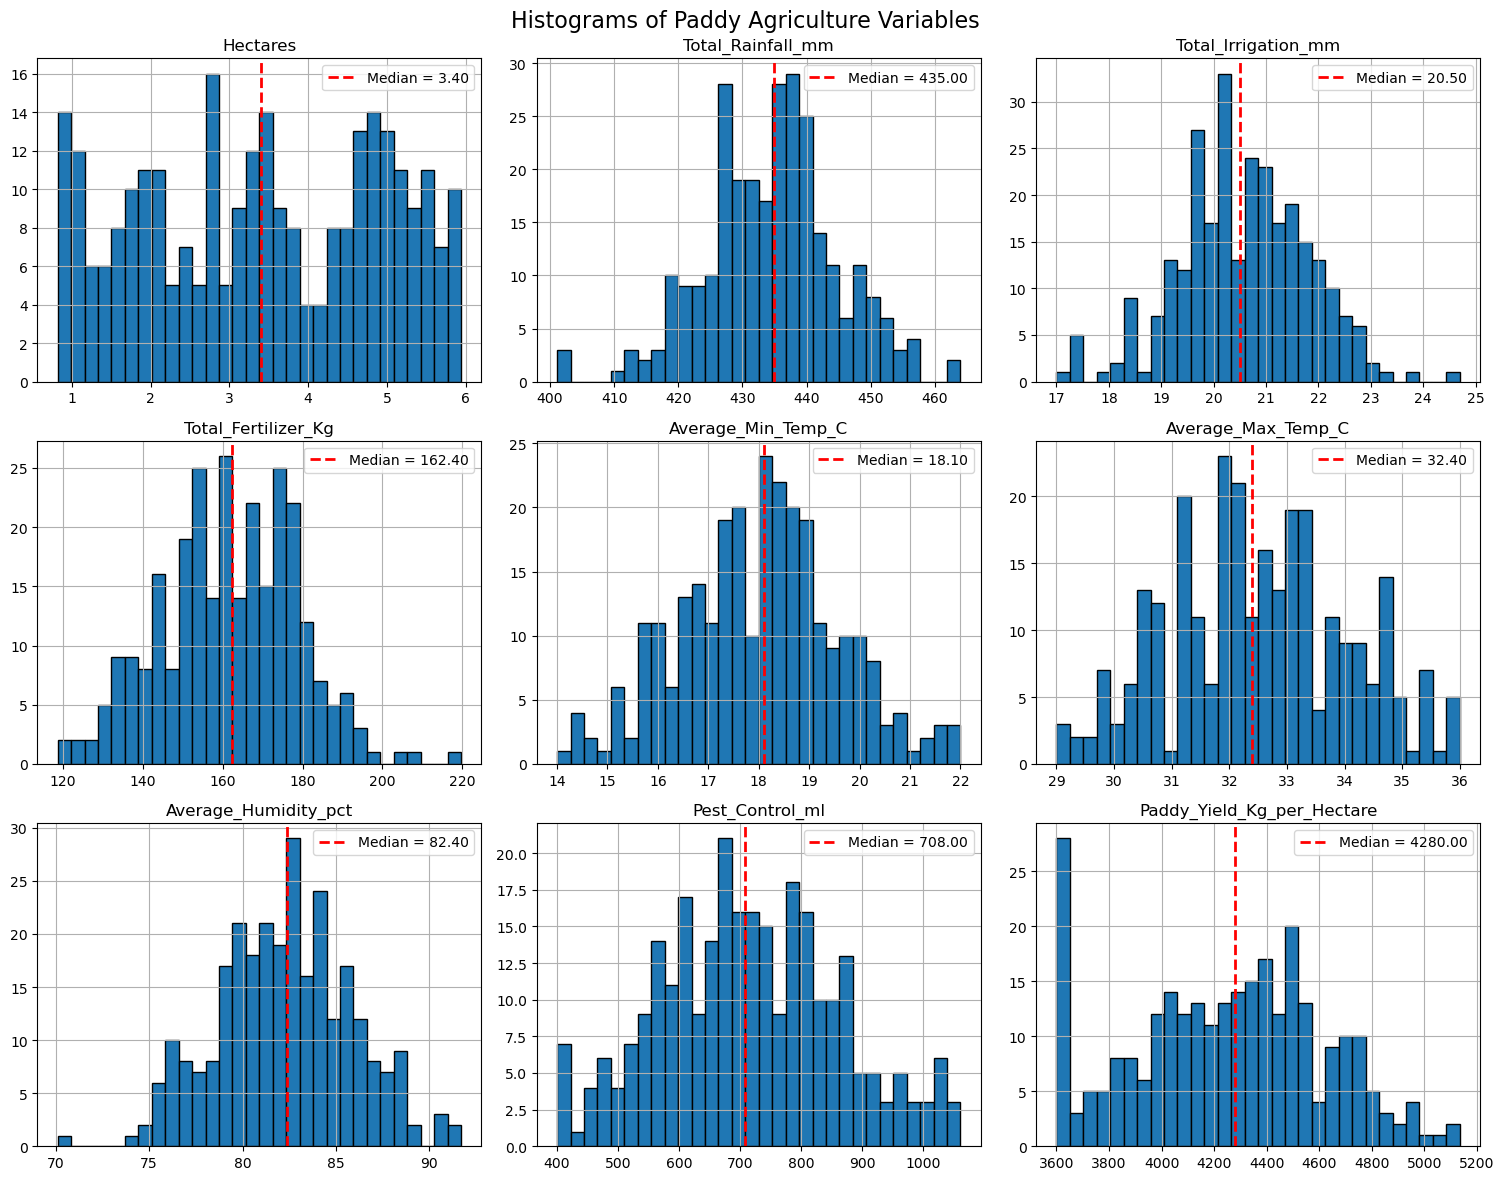

In [14]:
import matplotlib.pyplot as plt

numeric_cols = [
    "Hectares",
    "Total_Rainfall_mm",
    "Total_Irrigation_mm",
    "Total_Fertilizer_Kg",
    "Average_Min_Temp_C",
    "Average_Max_Temp_C",
    "Average_Humidity_pct",
    "Pest_Control_ml",
    "Paddy_Yield_Kg_per_Hectare"
]


axes = df[numeric_cols].hist(
    bins=30,
    figsize=(15, 12),
    edgecolor="black"
)


for ax, col in zip(axes.flatten(), numeric_cols):

    median = df[col].median()

    ax.axvline(
        median,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median:.2f}"
    )

    ax.legend()


plt.suptitle(
    "Histograms of Paddy Agriculture Variables",
    fontsize=16
)

plt.tight_layout()

plt.show()

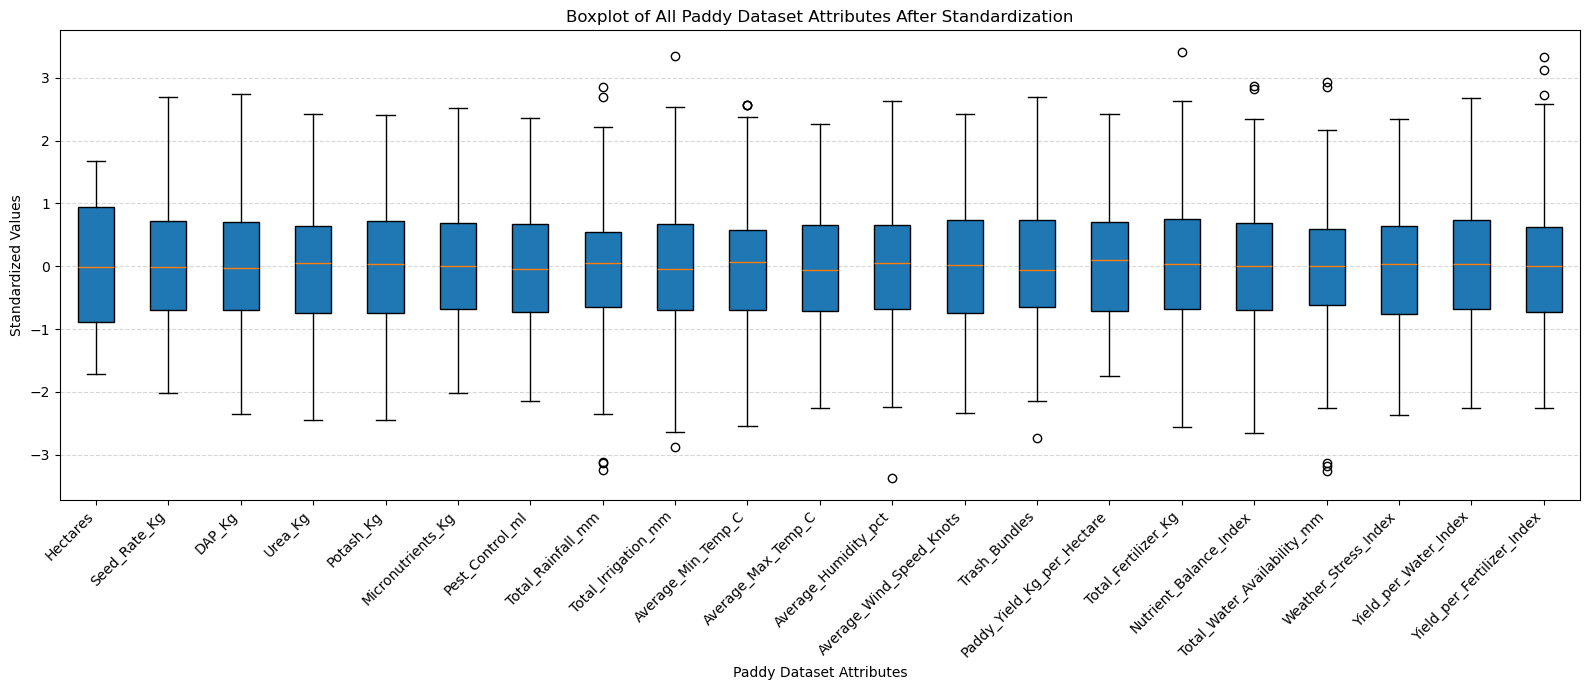

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Select only numerical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Create dataframe with numerical data
boxplot_data = df[numeric_columns].copy()

# Standardize the values
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    boxplot_data
)

# Convert scaled data back to dataframe
scaled_df = pd.DataFrame(
    scaled_data,
    columns=numeric_columns
)

# Create boxplot
plt.figure(
    figsize=(16, 7)
)

plt.boxplot(
    [scaled_df[column].dropna() for column in scaled_df.columns],
    labels=scaled_df.columns,
    patch_artist=True
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.xlabel(
    "Paddy Dataset Attributes"
)

plt.ylabel(
    "Standardized Values"
)

plt.title(
    "Boxplot of All Paddy Dataset Attributes After Standardization"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.show()

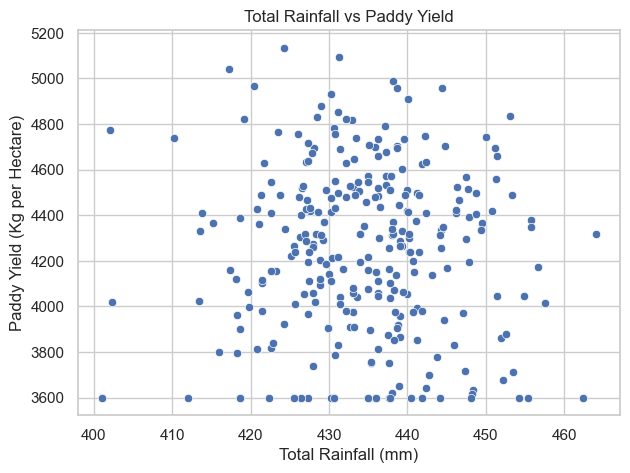

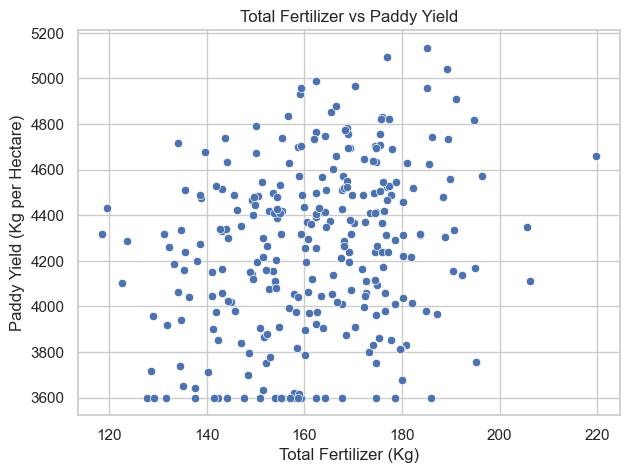

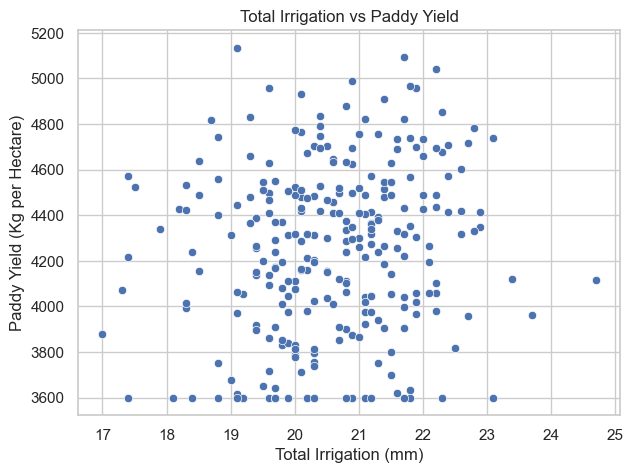

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")


# 1. Rainfall vs Paddy Yield
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=df["Total_Rainfall_mm"],
    y=df["Paddy_Yield_Kg_per_Hectare"]
)

plt.title("Total Rainfall vs Paddy Yield")

plt.xlabel("Total Rainfall (mm)")

plt.ylabel("Paddy Yield (Kg per Hectare)")

plt.show()


# 2. Total Fertilizer vs Paddy Yield
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=df["Total_Fertilizer_Kg"],
    y=df["Paddy_Yield_Kg_per_Hectare"]
)

plt.title("Total Fertilizer vs Paddy Yield")

plt.xlabel("Total Fertilizer (Kg)")

plt.ylabel("Paddy Yield (Kg per Hectare)")

plt.show()


# 3. Irrigation vs Paddy Yield
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=df["Total_Irrigation_mm"],
    y=df["Paddy_Yield_Kg_per_Hectare"]
)

plt.title("Total Irrigation vs Paddy Yield")

plt.xlabel("Total Irrigation (mm)")

plt.ylabel("Paddy Yield (Kg per Hectare)")

plt.show()


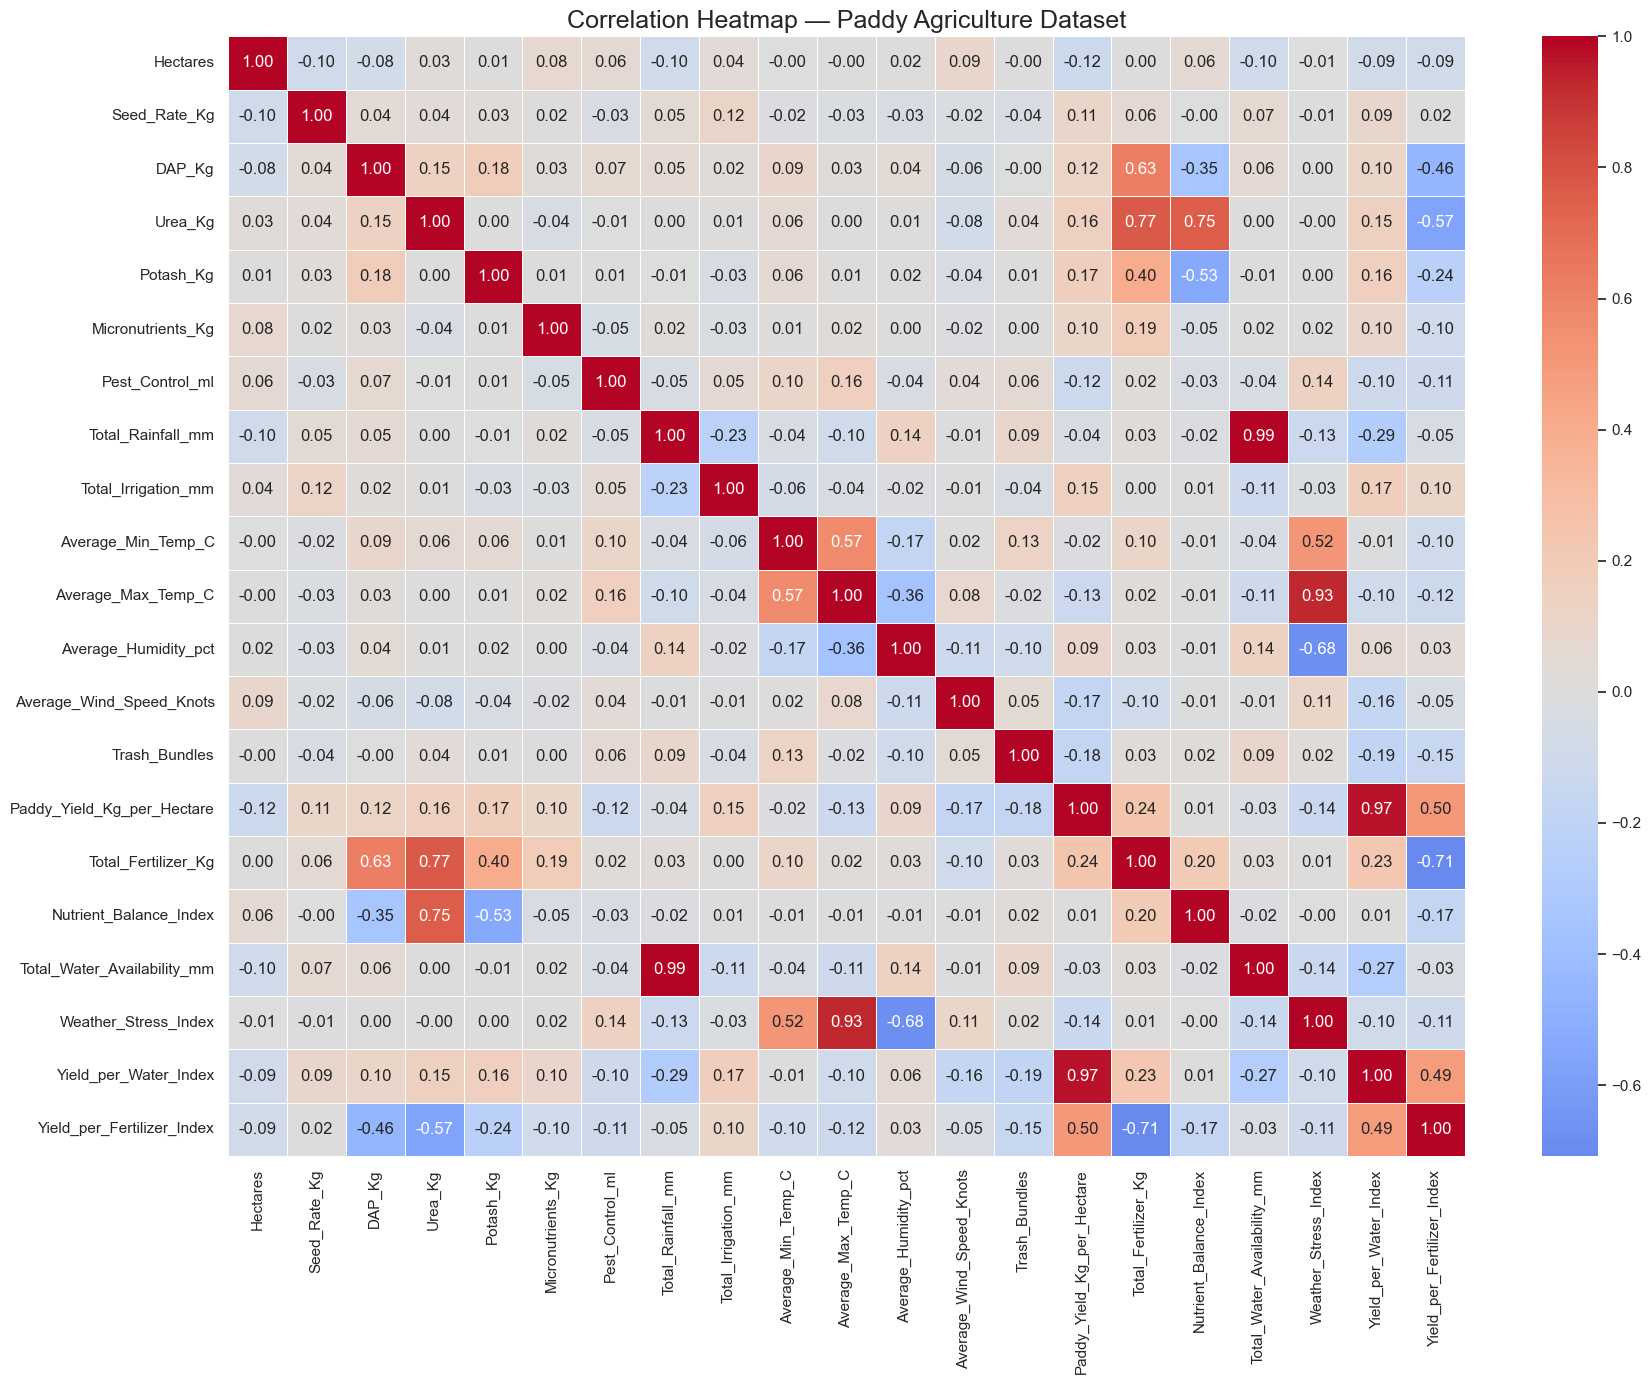

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Select only numerical columns
numeric_df = df.select_dtypes(
    include=["int64", "float64"]
)


# Calculate correlation
corr = numeric_df.corr()


# Create Heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)


plt.title(
    "Correlation Heatmap — Paddy Agriculture Dataset",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    "paddy_correlation_heatmap.png",
    dpi=300
)

plt.show()


Feature: Total_Rainfall_mm
R²: 0.0020157935853777342
RMSE: 367.8665708826802


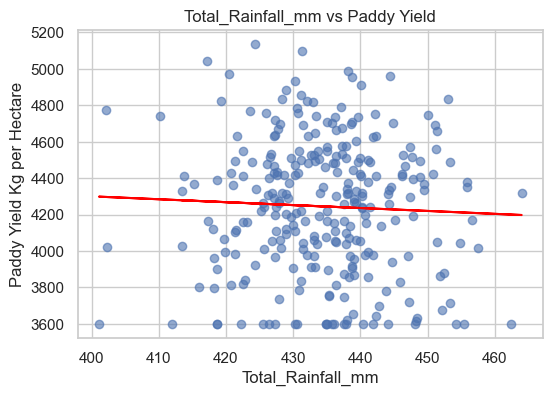


Feature: Total_Irrigation_mm
R²: 0.02142427413480885
RMSE: 364.27193198547457


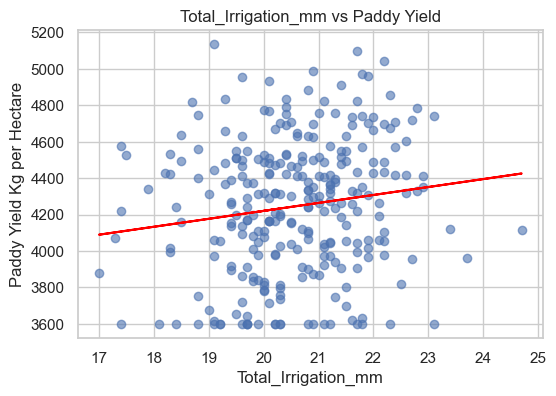


Feature: Total_Fertilizer_Kg
R²: 0.059355298677985724
RMSE: 357.1423044091344


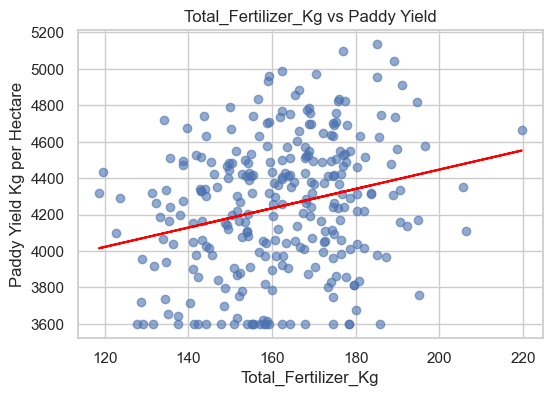


Feature: Average_Max_Temp_C
R²: 0.015625251850957533
RMSE: 365.3496721600247


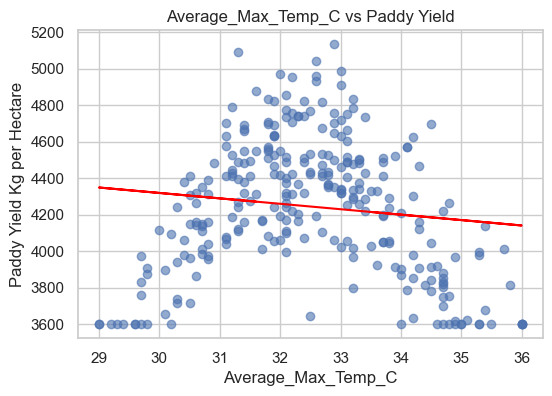


Feature: Average_Humidity_pct
R²: 0.008789061192479908
RMSE: 366.6160997780549


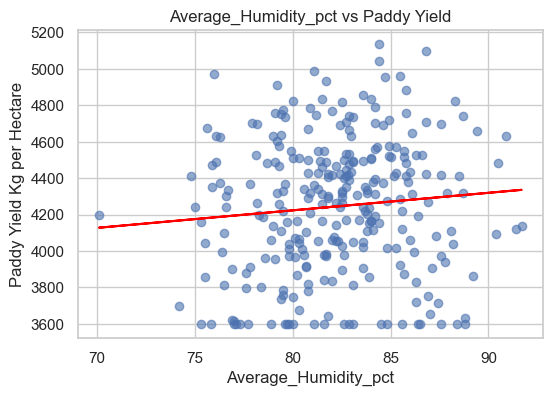


Feature: Pest_Control_ml
R²: 0.013318990908701034
RMSE: 365.77740496076075


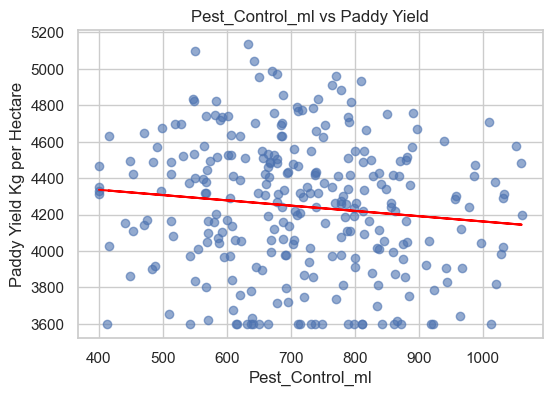

In [20]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    r2_score,
    mean_squared_error
)


# Target variable
y = df["Paddy_Yield_Kg_per_Hectare"]


# Selected numerical features
features = [
    "Total_Rainfall_mm",
    "Total_Irrigation_mm",
    "Total_Fertilizer_Kg",
    "Average_Max_Temp_C",
    "Average_Humidity_pct",
    "Pest_Control_ml"
]


for col in features:

    X = df[[col]]

    model = LinearRegression()

    model.fit(X, y)

    y_pred = model.predict(X)


    r2 = r2_score(
        y,
        y_pred
    )


    rmse = np.sqrt(
        mean_squared_error(
            y,
            y_pred
        )
    )


    print("\nFeature:", col)

    print("R²:", r2)

    print("RMSE:", rmse)


    plt.figure(figsize=(6, 4))

    plt.scatter(
        X,
        y,
        alpha=0.6
    )

    plt.plot(
        X,
        y_pred,
        color="red"
    )


    plt.title(
        f"{col} vs Paddy Yield"
    )

    plt.xlabel(col)

    plt.ylabel(
        "Paddy Yield Kg per Hectare"
    )

    plt.show()

In [21]:

# STEP 1: IMPORT LIBRARIES AND PREPARE DATA


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures
)

from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor

from sklearn.svm import SVR

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from scipy import stats



# SELECT FEATURES AND TARGET


features = [
    "Total_Rainfall_mm",
    "Total_Irrigation_mm",
    "Total_Fertilizer_Kg",
    "Average_Max_Temp_C",
    "Average_Humidity_pct"
]


X = df[features]

y = df["Paddy_Yield_Kg_per_Hectare"]



# TRAIN TEST SPLIT


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 224
Testing Samples: 56


MULTIPLE LINEAR REGRESSION RESULTS
R2 Score: 0.06587146078001593
MAE: 317.681088178927
MSE: 144220.66963879
RMSE: 379.76396569288926

Cross Validation Scores:
[-0.03093149 -0.00645892  0.06197692  0.15931348 -0.00786194]
Mean CV R2 Score: 0.03520761054724455


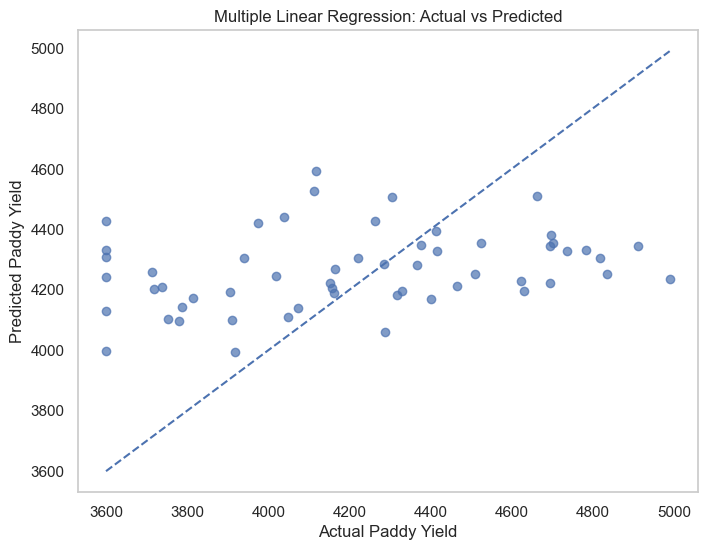

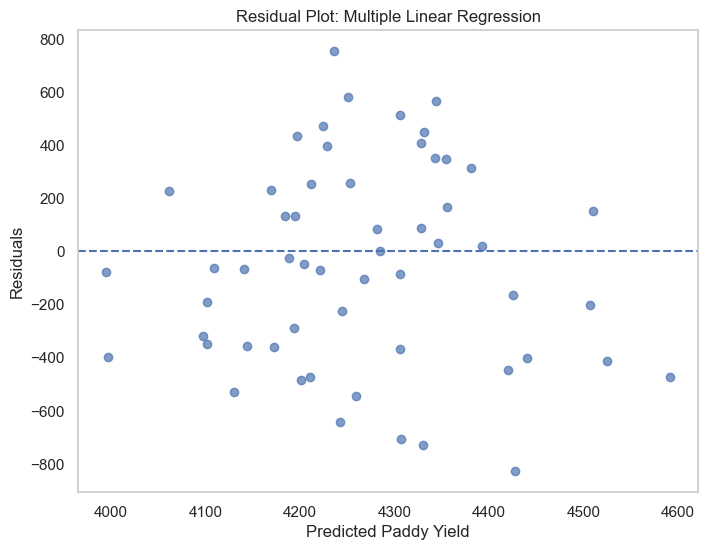

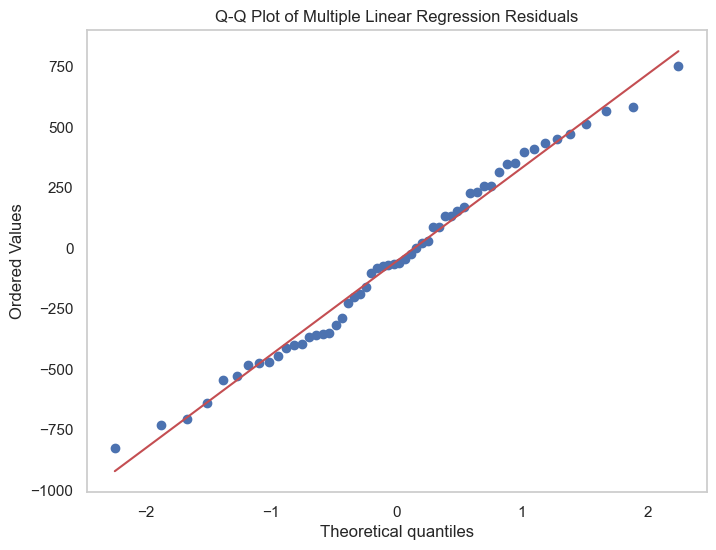

In [22]:

# MULTIPLE LINEAR REGRESSION


linear_model = LinearRegression()


# Train model
linear_model.fit(
    X_train,
    y_train
)


# Prediction
y_pred_linear = linear_model.predict(
    X_test
)



# EVALUATION METRICS


linear_r2 = r2_score(
    y_test,
    y_pred_linear
)

linear_mae = mean_absolute_error(
    y_test,
    y_pred_linear
)

linear_mse = mean_squared_error(
    y_test,
    y_pred_linear
)

linear_rmse = np.sqrt(
    linear_mse
)


print("=" * 45)
print("MULTIPLE LINEAR REGRESSION RESULTS")
print("=" * 45)

print("R2 Score:", linear_r2)
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)



# CROSS VALIDATION


linear_cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring="r2"
)


print("\nCross Validation Scores:")
print(linear_cv_scores)

print(
    "Mean CV R2 Score:",
    linear_cv_scores.mean()
)



# ACTUAL VS PREDICTED PLOT


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.7
)

plt.plot(
    [
        y_test.min(),
        y_test.max()
    ],
    [
        y_test.min(),
        y_test.max()
    ],
    linestyle="--"
)

plt.xlabel("Actual Paddy Yield")

plt.ylabel("Predicted Paddy Yield")

plt.title(
    "Multiple Linear Regression: Actual vs Predicted"
)

plt.grid()

plt.show()



# RESIDUAL PLOT


linear_residuals = (
    y_test -
    y_pred_linear
)


plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_linear,
    linear_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Paddy Yield"
)

plt.ylabel(
    "Residuals"
)

plt.title(
    "Residual Plot: Multiple Linear Regression"
)

plt.grid()

plt.show()



# Q-Q PLOT


plt.figure(figsize=(8, 6))

stats.probplot(
    linear_residuals,
    dist="norm",
    plot=plt
)

plt.title(
    "Q-Q Plot of Multiple Linear Regression Residuals"
)

plt.grid()

plt.show()

In [ ]:
 # SELECT NUMERICAL FEATURES

X_train_ridge = X_train.select_dtypes(include=np.number)

X_test_ridge = X_test.select_dtypes(include=np.number)


print("Training shape:", X_train_ridge.shape)
print("Testing shape:", X_test_ridge.shape)

RIDGE REGRESSION RESULTS
Best Parameters: {'ridge__alpha': 100}
Best CV R2 Score: 0.03576340355123431
Test R2 Score: 0.056873958970277805
MAE: 323.0944355566643
MSE: 145609.7993801425
RMSE: 381.5885210277459


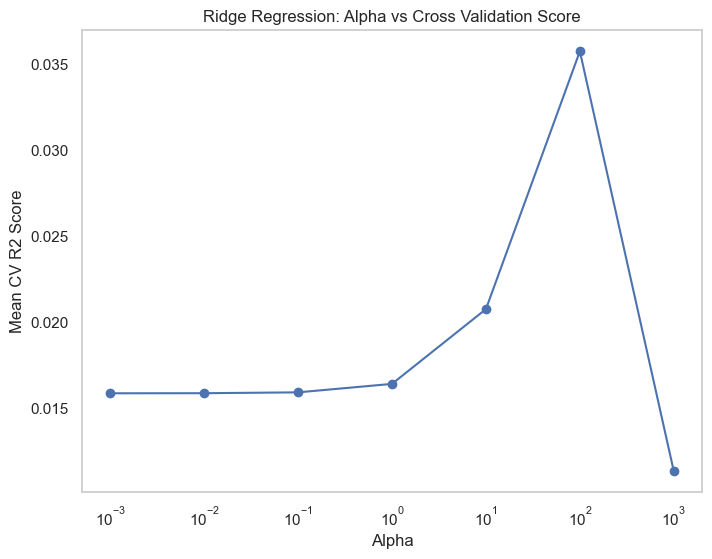

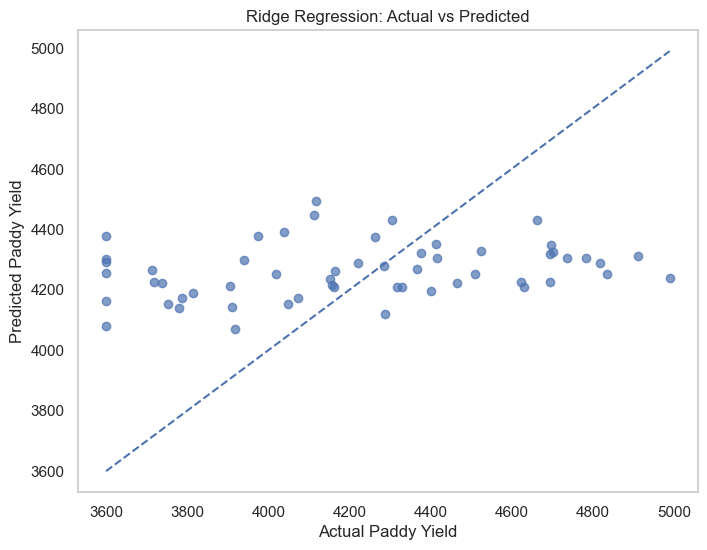

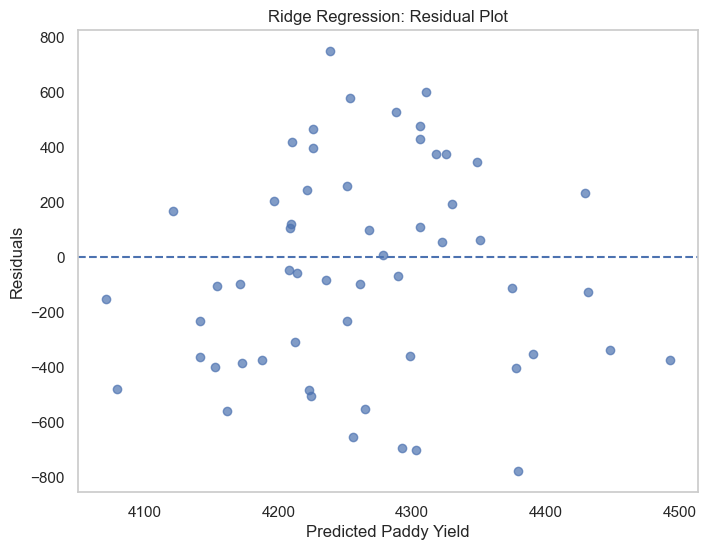

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures
)

from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor

from sklearn.svm import SVR

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from scipy import stats

# Re-define features and target for regression
features = [
    "Total_Rainfall_mm",
    "Total_Irrigation_mm",
    "Total_Fertilizer_Kg",
    "Average_Max_Temp_C",
    "Average_Humidity_pct"
]

X = df[features]
y = df["Paddy_Yield_Kg_per_Hectare"]

# Re-perform train-test split for regression
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================
# RIDGE REGRESSION
# WITH HYPERPARAMETER TUNING
# ============================================


ridge_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "ridge",
        Ridge()
    )

])


# ============================================
# HYPERPARAMETER VALUES
# ============================================

ridge_parameters = {

    "ridge__alpha": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]

}


# ============================================
# GRID SEARCH
# ============================================

ridge_grid = GridSearchCV(

    estimator=ridge_pipeline,

    param_grid=ridge_parameters,

    cv=5,

    scoring="r2",

    n_jobs=-1

)


# Train

ridge_grid.fit(
    X_train,
    y_train
)


# ============================================
# BEST MODEL
# ============================================

best_ridge_model = (
    ridge_grid.best_estimator_
)


# Prediction

y_pred_ridge = (
    best_ridge_model.predict(
        X_test
    )
)


# ============================================
# METRICS
# ============================================

ridge_r2 = r2_score(
    y_test,
    y_pred_ridge
)

ridge_mae = mean_absolute_error(
    y_test,
    y_pred_ridge
)

ridge_mse = mean_squared_error(
    y_test,
    y_pred_ridge
)

ridge_rmse = np.sqrt(
    ridge_mse
)


print("=" * 45)

print("RIDGE REGRESSION RESULTS")

print("=" * 45)

print(
    "Best Parameters:",
    ridge_grid.best_params_
)

print(
    "Best CV R2 Score:",
    ridge_grid.best_score_
)

print(
    "Test R2 Score:",
    ridge_r2
)

print(
    "MAE:",
    ridge_mae
)

print(
    "MSE:",
    ridge_mse
)

print(
    "RMSE:",
    ridge_rmse
)


# ============================================
# ALPHA VS CV SCORE PLOT
# ============================================

ridge_results = pd.DataFrame(
    ridge_grid.cv_results_
)


plt.figure(figsize=(8, 6))

plt.plot(
    ridge_results[
        "param_ridge__alpha"
    ].astype(float),

    ridge_results[
        "mean_test_score"
    ],

    marker="o"
)


plt.xscale(
    "log"
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Mean CV R2 Score"
)

plt.title(
    "Ridge Regression: Alpha vs Cross Validation Score"
)

plt.grid()

plt.show()


# ============================================
# ACTUAL VS PREDICTED
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_ridge,
    alpha=0.7
)

plt.plot(
    [
        y_test.min(),
        y_test.max()
    ],

    [
        y_test.min(),
        y_test.max()
    ],

    linestyle="--"
)

plt.xlabel(
    "Actual Paddy Yield"
)

plt.ylabel(
    "Predicted Paddy Yield"
)

plt.title(
    "Ridge Regression: Actual vs Predicted"
)

plt.grid()

plt.show()


# ============================================
# RESIDUAL PLOT
# ============================================

ridge_residuals = (
    y_test -
    y_pred_ridge
)


plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_ridge,
    ridge_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Paddy Yield"
)

plt.ylabel(
    "Residuals"
)

plt.title(
    "Ridge Regression: Residual Plot"
)

plt.grid()

plt.show()

LASSO REGRESSION RESULTS
Best Parameters: {'lasso__alpha': 10}
Best CV R2 Score: 0.024896594285738115
Test R2 Score: 0.06293622587389192
MAE: 320.4382999314126
MSE: 144673.84232962955
RMSE: 380.3601481880424


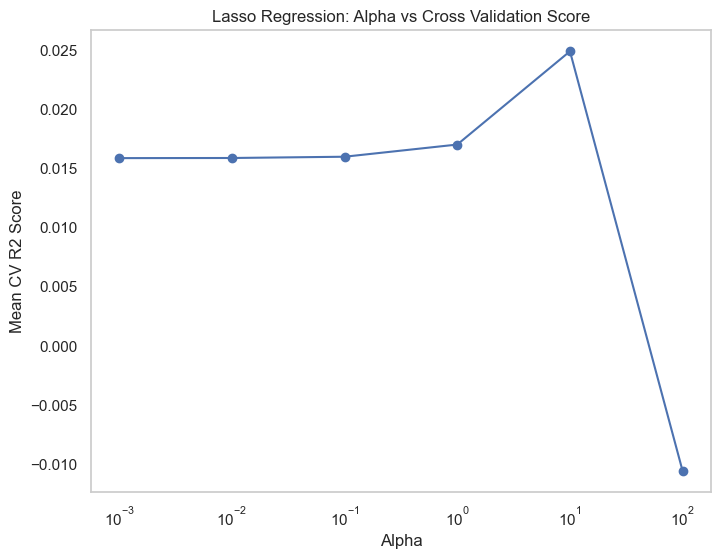

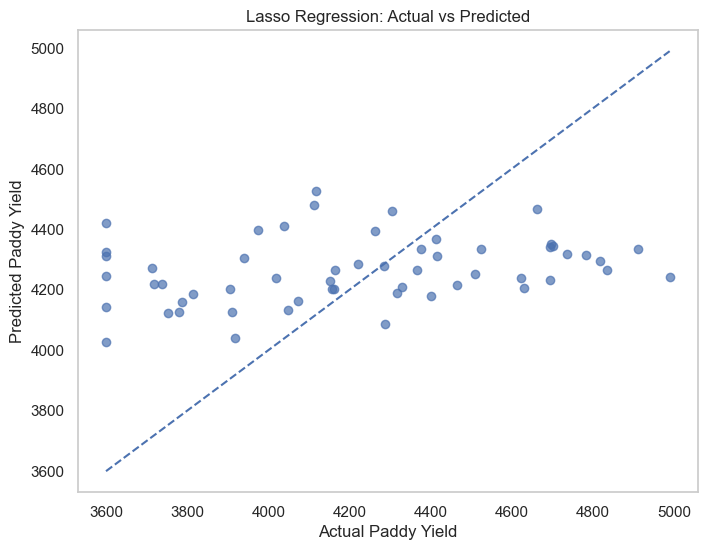

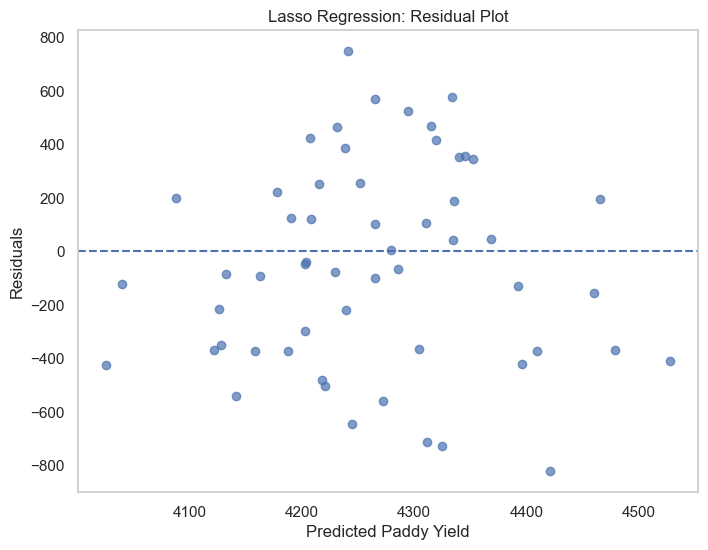

In [25]:
# ============================================
# LASSO REGRESSION
# WITH HYPERPARAMETER TUNING
# ============================================


lasso_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "lasso",
        Lasso(
            max_iter=10000
        )
    )

])


# ============================================
# HYPERPARAMETERS
# ============================================

lasso_parameters = {

    "lasso__alpha": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]

}


# ============================================
# GRID SEARCH
# ============================================

lasso_grid = GridSearchCV(

    estimator=lasso_pipeline,

    param_grid=lasso_parameters,

    cv=5,

    scoring="r2",

    n_jobs=-1

)


# Train

lasso_grid.fit(
    X_train,
    y_train
)


# Best model

best_lasso_model = (
    lasso_grid.best_estimator_
)


# Prediction

y_pred_lasso = (
    best_lasso_model.predict(
        X_test
    )
)


# ============================================
# METRICS
# ============================================

lasso_r2 = r2_score(
    y_test,
    y_pred_lasso
)

lasso_mae = mean_absolute_error(
    y_test,
    y_pred_lasso
)

lasso_mse = mean_squared_error(
    y_test,
    y_pred_lasso
)

lasso_rmse = np.sqrt(
    lasso_mse
)


print("=" * 45)

print("LASSO REGRESSION RESULTS")

print("=" * 45)

print(
    "Best Parameters:",
    lasso_grid.best_params_
)

print(
    "Best CV R2 Score:",
    lasso_grid.best_score_
)

print(
    "Test R2 Score:",
    lasso_r2
)

print(
    "MAE:",
    lasso_mae
)

print(
    "MSE:",
    lasso_mse
)

print(
    "RMSE:",
    lasso_rmse
)


# ============================================
# ALPHA VS CV SCORE PLOT
# ============================================

lasso_results = pd.DataFrame(
    lasso_grid.cv_results_
)


plt.figure(figsize=(8, 6))

plt.plot(

    lasso_results[
        "param_lasso__alpha"
    ].astype(float),

    lasso_results[
        "mean_test_score"
    ],

    marker="o"
)


plt.xscale(
    "log"
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Mean CV R2 Score"
)

plt.title(
    "Lasso Regression: Alpha vs Cross Validation Score"
)

plt.grid()

plt.show()


# ============================================
# ACTUAL VS PREDICTED
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_lasso,
    alpha=0.7
)

plt.plot(

    [
        y_test.min(),
        y_test.max()
    ],

    [
        y_test.min(),
        y_test.max()
    ],

    linestyle="--"
)


plt.xlabel(
    "Actual Paddy Yield"
)

plt.ylabel(
    "Predicted Paddy Yield"
)

plt.title(
    "Lasso Regression: Actual vs Predicted"
)

plt.grid()

plt.show()


# ============================================
# RESIDUAL PLOT
# ============================================

lasso_residuals = (
    y_test -
    y_pred_lasso
)


plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_lasso,
    lasso_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Paddy Yield"
)

plt.ylabel(
    "Residuals"
)

plt.title(
    "Lasso Regression: Residual Plot"
)

plt.grid()

plt.show()

In [ ]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Features
features = [
    "Total_Rainfall_mm",
    "Total_Irrigation_mm",
    "Total_Fertilizer_Kg",
    "Average_Max_Temp_C",
    "Average_Humidity_pct"
]

X = df[features]

# Numerical target
y = df["Paddy_Yield_Kg_per_Hectare"]


# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# Create model
linear_model = LinearRegression()


# Train model
linear_model.fit(
    X_train,
    y_train
)


# Prediction
y_pred_linear = linear_model.predict(
    X_test
)


# Evaluation
linear_r2 = r2_score(
    y_test,
    y_pred_linear
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

linear_mae = mean_absolute_error(
    y_test,
    y_pred_linear
)


print("MULTIPLE LINEAR REGRESSION")
print("--------------------------")
print("R2 Score:", linear_r2)
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Scale data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)


# Ridge model
ridge_model = Ridge(
    alpha=1.0
)

ridge_model.fit(
    X_train_scaled,
    y_train
)


# Prediction
y_pred_ridge = ridge_model.predict(
    X_test_scaled
)


# Evaluation
ridge_r2 = r2_score(
    y_test,
    y_pred_ridge
)

ridge_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_ridge
    )
)

ridge_mae = mean_absolute_error(
    y_test,
    y_pred_ridge
)


print("RIDGE REGRESSION")
print("----------------")
print("R2 Score:", ridge_r2)
print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)

RIDGE REGRESSION
----------------
R2 Score: 0.0658300207557897
MAE: 317.7647804932758
RMSE: 379.77238918748606


In [27]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(
    alpha=0.1,
    max_iter=10000
)

lasso_model.fit(
    X_train_scaled,
    y_train
)


# Prediction
y_pred_lasso = lasso_model.predict(
    X_test_scaled
)


# Evaluation
lasso_r2 = r2_score(
    y_test,
    y_pred_lasso
)

lasso_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_lasso
    )
)

lasso_mae = mean_absolute_error(
    y_test,
    y_pred_lasso
)


print("LASSO REGRESSION")
print("----------------")
print("R2 Score:", lasso_r2)
print("MAE:", lasso_mae)
print("RMSE:", lasso_rmse)

LASSO REGRESSION
----------------
R2 Score: 0.06587181206848525
MAE: 317.7086605972981
RMSE: 379.76389428584565


In [28]:
import pandas as pd

comparison_df = pd.DataFrame({

    "Model": [
        "Multiple Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "R2 Score": [
        linear_r2,
        ridge_r2,
        lasso_r2
    ],

    "MAE": [
        linear_mae,
        ridge_mae,
        lasso_mae
    ],

    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse
    ]
})

# Sort from lowest RMSE to highest
comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
)

print(comparison_df)

                        Model  R2 Score         MAE        RMSE
2            Lasso Regression  0.065872  317.708661  379.763894
0  Multiple Linear Regression  0.065871  317.681088  379.763966
1            Ridge Regression  0.065830  317.764780  379.772389


Yield_Level_Model
High      94
Medium    93
Low       93
Name: count, dtype: int64

Decision Tree Accuracy: 0.875

Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.89      0.94        19
         Low       0.94      0.79      0.86        19
      Medium       0.74      0.94      0.83        18

    accuracy                           0.88        56
   macro avg       0.89      0.88      0.88        56
weighted avg       0.89      0.88      0.88        56



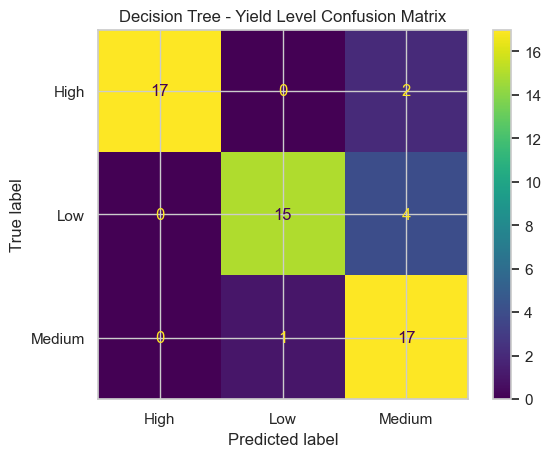

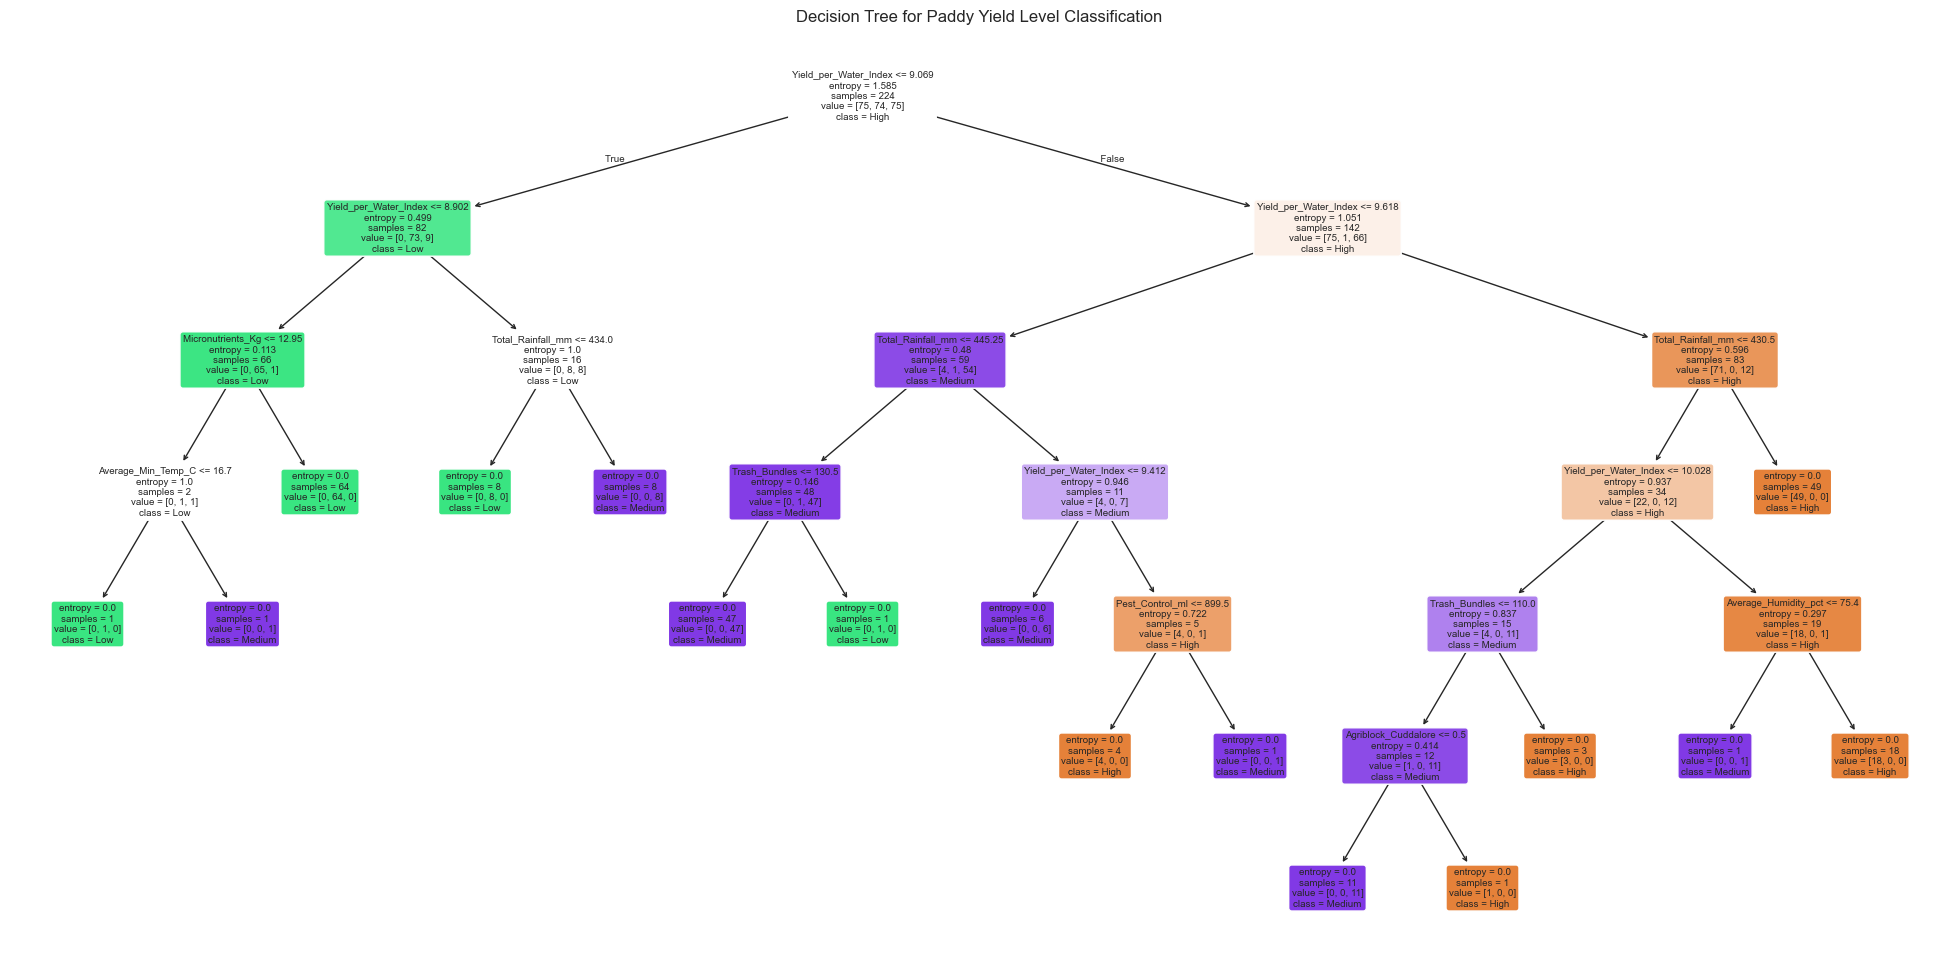

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# Create Yield Level if needed
def yield_level(x):

    if x <= df[
        "Paddy_Yield_Kg_per_Hectare"
    ].quantile(0.33):

        return "Low"

    elif x <= df[
        "Paddy_Yield_Kg_per_Hectare"
    ].quantile(0.66):

        return "Medium"

    else:

        return "High"


df["Yield_Level_Model"] = df[
    "Paddy_Yield_Kg_per_Hectare"
].apply(
    yield_level
)


print(
    df[
        "Yield_Level_Model"
    ].value_counts()
)


# Target
y = df[
    "Yield_Level_Model"
]


# Features
X = df.drop(
    [
        "Yield_Level_Model",
        "Paddy_Yield_Kg_per_Hectare",
        "Yield_Level"
    ],
    axis=1,
    errors="ignore"
)


# Convert categorical variables
X = pd.get_dummies(
    X,
    drop_first=True
)


# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# Decision Tree
model = DecisionTreeClassifier(

    criterion="entropy",

    max_depth=6,

    min_samples_split=2,

    min_samples_leaf=1,

    random_state=42
)


# Train
model.fit(
    X_train,
    y_train
)


# Prediction
y_pred = model.predict(
    X_test
)


# Accuracy
accuracy = accuracy_score(
    y_test,
    y_pred
)


print(
    "\nDecision Tree Accuracy:",
    accuracy
)


# Classification report
print(
    "\nClassification Report:"
)


print(
    classification_report(
        y_test,
        y_pred
    )
)


# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)


disp.plot()

plt.title(
    "Decision Tree - Yield Level Confusion Matrix"
)

plt.show()


# Tree visualization
plt.figure(
    figsize=(25, 12)
)


plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=7
)


plt.title(
    "Decision Tree for Paddy Yield Level Classification"
)

plt.show()


Random Forest Accuracy: 0.9107142857142857

Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.84      0.91        19
         Low       1.00      0.89      0.94        19
      Medium       0.78      1.00      0.88        18

    accuracy                           0.91        56
   macro avg       0.93      0.91      0.91        56
weighted avg       0.93      0.91      0.91        56



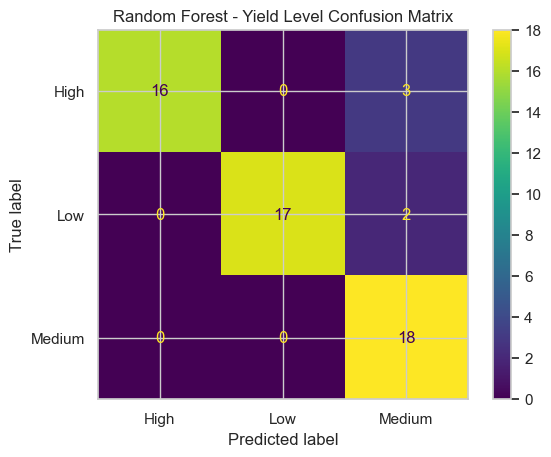

In [32]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# Random Forest
model = RandomForestClassifier(

    n_estimators=200,

    criterion="gini",

    max_depth=8,

    min_samples_split=2,

    min_samples_leaf=1,

    max_features="sqrt",

    bootstrap=True,

    random_state=42
)


# Train model
model.fit(
    X_train,
    y_train
)


# Prediction
y_pred = model.predict(
    X_test
)


# Accuracy
accuracy = accuracy_score(
    y_test,
    y_pred
)


print(
    "\nRandom Forest Accuracy:",
    accuracy
)


# Classification Report
print(
    "\nClassification Report:"
)


print(
    classification_report(
        y_test,
        y_pred
    )
)


# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)


disp.plot()

plt.title(
    "Random Forest - Yield Level Confusion Matrix"
)


plt.show()

In [34]:
# ============================================
# RESET REGRESSION DATA FOR SVR
# ============================================

from sklearn.model_selection import train_test_split

features = [
    "Total_Rainfall_mm",
    "Total_Irrigation_mm",
    "Total_Fertilizer_Kg",
    "Average_Max_Temp_C",
    "Average_Humidity_pct"
]

# Input features
X = df[features]

# Numerical target
y = df["Paddy_Yield_Kg_per_Hectare"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Target:", y_train.head())

X_train: (224, 5)
y_train: (224,)
Target: 86     3868.0
137    4507.0
184    4509.0
5      4418.0
124    4671.0
Name: Paddy_Yield_Kg_per_Hectare, dtype: float64


In [35]:
 # ============================================
# SUPPORT VECTOR REGRESSION (SVR)
# WITH HYPERPARAMETER TUNING
# ============================================

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import matplotlib.pyplot as plt


# ============================================
# CREATE SVR PIPELINE
# ============================================

svr_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "svr",
        SVR()
    )

])


# ============================================
# HYPERPARAMETER VALUES
# ============================================

svr_parameters = {

    "svr__kernel": [
        "rbf"
    ],

    "svr__C": [
        1,
        10,
        100
    ],

    "svr__epsilon": [
        0.01,
        0.1,
        1
    ],

    "svr__gamma": [
        "scale",
        "auto"
    ]

}


# ============================================
# GRID SEARCH
# ============================================

svr_grid = GridSearchCV(

    estimator=svr_pipeline,

    param_grid=svr_parameters,

    cv=5,

    scoring="r2",

    n_jobs=-1

)


# ============================================
# TRAIN THE MODEL
# ============================================

svr_grid.fit(
    X_train,
    y_train
)


# ============================================
# BEST MODEL
# ============================================

best_svr_model = (
    svr_grid.best_estimator_
)


# ============================================
# PREDICTION
# ============================================

y_pred_svr = (
    best_svr_model.predict(
        X_test
    )
)


# ============================================
# CALCULATE METRICS
# ============================================

svr_r2 = r2_score(
    y_test,
    y_pred_svr
)

svr_mae = mean_absolute_error(
    y_test,
    y_pred_svr
)

svr_mse = mean_squared_error(
    y_test,
    y_pred_svr
)

svr_rmse = np.sqrt(
    svr_mse
)


# ============================================
# PRINT RESULTS
# ============================================

print("=" * 45)

print(
    "SUPPORT VECTOR REGRESSION RESULTS"
)

print("=" * 45)

print(
    "Best Parameters:",
    svr_grid.best_params_
)

print(
    "Best CV R2 Score:",
    svr_grid.best_score_
)

print(
    "Test R2 Score:",
    svr_r2
)

print(
    "MAE:",
    svr_mae
)

print(
    "MSE:",
    svr_mse
)

print(
    "RMSE:",
    svr_rmse
)

SUPPORT VECTOR REGRESSION RESULTS
Best Parameters: {'svr__C': 100, 'svr__epsilon': 1, 'svr__gamma': 'auto', 'svr__kernel': 'rbf'}
Best CV R2 Score: 0.36425903436175
Test R2 Score: 0.465024040735991
MAE: 239.27623440695555
MSE: 82595.26162227635
RMSE: 287.3939136834257


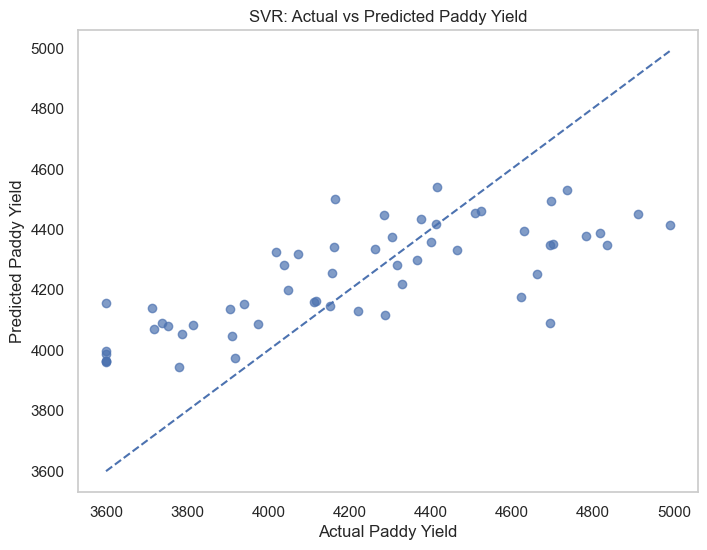

In [36]:
# ============================================
# ACTUAL VS PREDICTED PLOT
# ============================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    y_test,
    y_pred_svr,
    alpha=0.7
)


# PERFECT PREDICTION LINE

plt.plot(

    [
        y_test.min(),
        y_test.max()
    ],

    [
        y_test.min(),
        y_test.max()
    ],

    linestyle="--"

)


plt.xlabel(
    "Actual Paddy Yield"
)

plt.ylabel(
    "Predicted Paddy Yield"
)

plt.title(
    "SVR: Actual vs Predicted Paddy Yield"
)

plt.grid()

plt.show()

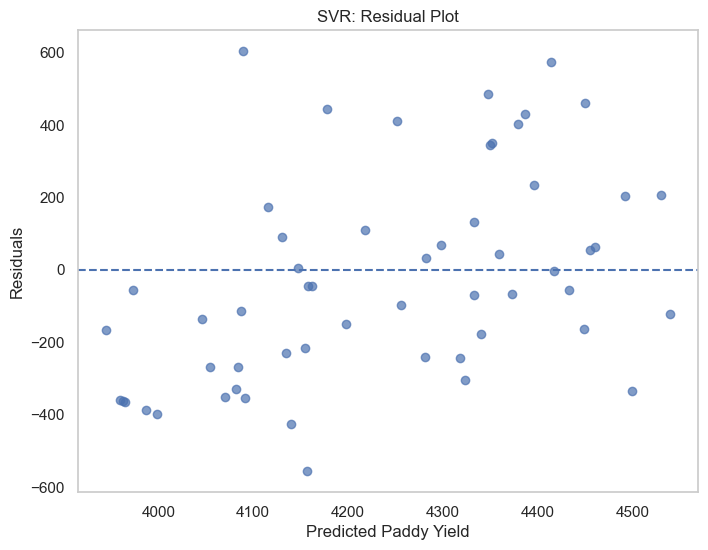

In [37]:
# ============================================
# RESIDUAL PLOT
# ============================================

svr_residuals = (
    y_test -
    y_pred_svr
)


plt.figure(
    figsize=(8, 6)
)


plt.scatter(
    y_pred_svr,
    svr_residuals,
    alpha=0.7
)


plt.axhline(

    y=0,

    linestyle="--"

)


plt.xlabel(
    "Predicted Paddy Yield"
)

plt.ylabel(
    "Residuals"
)

plt.title(
    "SVR: Residual Plot"
)

plt.grid()

plt.show()

In [39]:
# ============================================
# FINAL MODEL COMPARISON
# ============================================

comparison_df = pd.DataFrame({

    "Model": [

        "Multiple Linear Regression",

        "Ridge Regression",

        "Lasso Regression",

        "Support Vector Regression"

    ],

    "R2 Score": [

        linear_r2,

        ridge_r2,

        lasso_r2,

        svr_r2

    ],

    "MAE": [

        linear_mae,

        ridge_mae,

        lasso_mae,

        svr_mae

    ],

    "RMSE": [

        linear_rmse,

        ridge_rmse,

        lasso_rmse,

        svr_rmse

    ]

})

# Sort by RMSE

comparison_df = comparison_df.sort_values(

    by="RMSE",

    ascending=True

)


print(
    comparison_df
)

                        Model  R2 Score         MAE        RMSE
3   Support Vector Regression  0.465024  239.276234  287.393914
2            Lasso Regression  0.065872  317.708661  379.763894
0  Multiple Linear Regression  0.065871  317.681088  379.763966
1            Ridge Regression  0.065830  317.764780  379.772389


In [40]:
df.to_csv("paddy_dashboard_data.csv", index=False)